In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from pathlib import Path
import seaborn as sns
from utils import construct_path, read_feather_gcs, pq_to_xy



/home/guardomayas/miniforge3/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Packages loaded successfully


In [ ]:
### LOAD DATA
DATASET = "malecns_09"
SUBSET_NAME = "optic"
DATA_PATH = "connectome_data"
pin_data  = 'pin_data'
out_dir = Path("connectome_data/processed")
dataset_base = DATASET.split("_")[0]  # "malecns"

if SUBSET_NAME is not None:
    edgelist_path = (
        f"{DATA_PATH}/{dataset_base}/"
        f"{dataset_base}_{SUBSET_NAME}_{DATASET}_{SUBSET_NAME}_simple_edgelist.feather"
    )

    synapses_path = (
        f"{DATA_PATH}/{dataset_base}/"
        f"{dataset_base}_{SUBSET_NAME}_{DATASET}_{SUBSET_NAME}_synapses.feather"
    )
    pin_data_path = (
        f"{DATA_PATH}/{dataset_base}/")
    print(f"Using subset: {SUBSET_NAME}")
else:
    edgelist_path = construct_path(DATA_PATH, DATASET, "edgelist_simple")
    synapses_path = construct_path(DATA_PATH, DATASET, "synapses")
    print("Using full dataset")

meta_path = construct_path(DATA_PATH, DATASET, "meta")
print(f"Meta path: {meta_path}")
print(f"Edgelist path: {edgelist_path}")

##Nodes and edges
meta = read_feather_gcs(meta_path, gcs_fs=None)
meta["malecns_09_id"] = meta["malecns_09_id"].astype("int64")

nodes_df = meta.query("region == 'optic_lobe'").copy().reset_index(drop=True)
cols_to_keep= ['malecns_09_id', 'side', 'cell_type','neurotransmitter_predicted', 'neurotransmitter_score',
                'hex_1', 'hex_2',
                ]
nodes_df.rename(columns={"optic_lobe_hex_1": "hex_1",
                               "optic_lobe_hex_2": "hex_2"
                               }, inplace=True)
nodes_df = nodes_df[cols_to_keep].reset_index(drop=True)

edgelist = read_feather_gcs(edgelist_path, gcs_fs=None)
edgelist = edgelist[edgelist["count"] > 3].copy().reset_index(drop=True)


Using subset: optic
Meta path: connectome_data/malecns/malecns_09_meta.feather
Edgelist path: connectome_data/malecns/malecns_optic_malecns_09_optic_simple_edgelist.feather
✓ Loaded 165,114 rows
✓ Loaded 6,629,951 rows


In [3]:
## Add p q coordinates 
nodes_df["hex_1"] = pd.to_numeric(
    nodes_df["hex_1"], errors="coerce"
)
nodes_df["hex_2"] = pd.to_numeric(
    nodes_df["hex_2"], errors="coerce"
)
nodes_df["p"] = nodes_df["hex_1"] - 18
nodes_df["q"] = nodes_df["hex_2"] - 19
nodes_df.head()

,malecns_09_id,side,cell_type,neurotransmitter_predicted,neurotransmitter_score,hex_1,hex_2,p,q
0,11901,right,5thsLNv_LNd6,unclear,0.491188,NaN,NaN,NaN,NaN
1,12254,right,5thsLNv_LNd6,acetylcholine,0.531692,NaN,NaN,NaN,NaN
2,13531,left,5thsLNv_LNd6,acetylcholine,0.544733,NaN,NaN,NaN,NaN
3,14633,left,5thsLNv_LNd6,unclear,0.458165,NaN,NaN,NaN,NaN
4,15319,right,AOTU045,glutamate,0.804108,NaN,NaN,NaN,NaN


In [16]:
columnar_nodes = nodes_df.query(
    "hex_1.notna() and hex_2.notna()"
).copy().reset_index(drop=True)

print("Columnar cell types:")
print(columnar_nodes["cell_type"].unique())
# Optional: clean dtypes before saving
columnar_nodes["malecns_09_id"] = columnar_nodes["malecns_09_id"].astype("int64")
columnar_nodes["cell_type"] = columnar_nodes["cell_type"].astype("string")
columnar_nodes["side"] = columnar_nodes["side"].astype("string")
columnar_nodes.to_feather(out_dir / "columnar_nodes.feather")
columnar_nodes.head()

Columnar cell types:
['C2' 'C3' 'L1' 'L2' 'L3' 'L5' 'Mi1' 'Mi4' 'Mi9' 'T1' 'Tm1' 'Tm2' 'Tm20'
 'Tm4' 'Tm9']


,malecns_09_id,side,cell_type,neurotransmitter_predicted,neurotransmitter_score,hex_1,hex_2,p,q
0,100043,right,C2,gaba,0.528316,24.0,17.0,6.0,-2.0
1,100062,right,C2,unclear,0.398571,24.0,35.0,6.0,16.0
2,100134,right,C2,unclear,0.405942,22.0,31.0,4.0,12.0
3,100156,right,C2,unclear,0.467389,28.0,38.0,10.0,19.0
4,100229,right,C2,unclear,0.581083,27.0,13.0,9.0,-6.0


In [5]:
columnar_nodes

,malecns_09_id,side,cell_type,neurotransmitter_predicted,neurotransmitter_score,hex_1,hex_2,p,q
0,100043,right,C2,gaba,0.528316,24.0,17.0,6.0,-2.0
1,100062,right,C2,unclear,0.398571,24.0,35.0,6.0,16.0
2,100134,right,C2,unclear,0.405942,22.0,31.0,4.0,12.0
3,100156,right,C2,unclear,0.467389,28.0,38.0,10.0,19.0
4,100229,right,C2,unclear,0.581083,27.0,13.0,9.0,-6.0
...,...,...,...,...,...,...,...,...,...
23715,99591,left,Tm9,acetylcholine,0.974427,17.0,6.0,-1.0,-13.0
23716,99729,left,Tm9,acetylcholine,0.959740,12.0,13.0,-6.0,-6.0
23717,99798,right,Tm9,acetylcholine,0.959936,10.0,15.0,-8.0,-4.0
23718,99825,right,Tm9,acetylcholine,0.974427,10.0,17.0,-8.0,-2.0


## Infer and add columns to T4 T5

In [6]:
from scipy.optimize import linear_sum_assignment
import pandas as pd
import numpy as np

def assign_home_col_from_inputs(
    col_nodes,
    nodes_df,
    edgelist,
    input_types=("Mi1",),
    post_types=("T4a", "T4b", "T4c", "T4d"),
    id_col="malecns_09_id",
    count_col="count",
):
    if isinstance(input_types, str):
        input_types = (input_types,)

    # -------------------------
    # Input cells with known columns
    # -------------------------
    central_input_nodes = (
        col_nodes
        .query("cell_type in @input_types")
        .copy()
        .reset_index(drop=True)
    )

    central_input_nodes["column_id"] = (
        central_input_nodes["side"].astype(str)
        + "_"
        + central_input_nodes["hex_1"].astype("Int64").astype(str)
        + "_"
        + central_input_nodes["hex_2"].astype("Int64").astype(str)
    )

    central_cols = central_input_nodes[
        [
            id_col,
            "cell_type",
            "side",
            "hex_1",
            "hex_2",
            "p",
            "q",
            "column_id",
        ]
    ].rename(
        columns={
            id_col: "pre",
            "cell_type": "pre_type",
            "side": "pre_side",
        }
    )

    # -------------------------
    # Add pre/post type and side
    # -------------------------
    node_info = nodes_df[
        [id_col, "cell_type", "side"]
    ].copy()

    edges_typed = (
        edgelist
        .merge(
            node_info.rename(
                columns={
                    id_col: "pre",
                    "cell_type": "pre_type",
                    "side": "pre_side",
                }
            ),
            on="pre",
            how="left",
        )
        .merge(
            node_info.rename(
                columns={
                    id_col: "post",
                    "cell_type": "post_type",
                    "side": "post_side",
                }
            ),
            on="post",
            how="left",
        )
    )

    # Only same-side edges
    edges_typed = edges_typed[
        edges_typed["pre_side"].notna()
        & edges_typed["post_side"].notna()
        & (edges_typed["pre_side"] == edges_typed["post_side"])
    ].copy()

    central_T_edges = edges_typed[
        edges_typed["pre_type"].isin(input_types)
        & edges_typed["post_type"].isin(post_types)
    ].copy()

    central_T_edges = central_T_edges.merge(
        central_cols,
        on=["pre", "pre_type", "pre_side"],
        how="inner",
    )

    column_table = (
        central_input_nodes[
            ["column_id", "side", "hex_1", "hex_2", "p", "q"]
        ]
        .drop_duplicates("column_id")
        .reset_index(drop=True)
    )

    matched_parts = []

    # -------------------------
    # Match separately by side and post type
    # -------------------------
    for side in sorted(column_table["side"].dropna().unique()):
        side_columns = column_table.query("side == @side").copy()

        for post_type in post_types:
            sub = central_T_edges.query(
                "post_type == @post_type and pre_side == @side and post_side == @side"
            ).copy()

            if sub.empty:
                print(f"No edges found for {input_types} → {post_type} on side {side}")
                continue

            post_ids = (
                nodes_df.query("cell_type == @post_type and side == @side")[id_col]
                .drop_duplicates()
                .to_numpy()
            )

            col_ids = side_columns["column_id"].to_numpy()

            if len(post_ids) == 0 or len(col_ids) == 0:
                print(f"No posts or columns for {post_type} on side {side}")
                continue

            scores = (
                sub
                .groupby(["column_id", "post"], as_index=False)[count_col]
                .sum()
            )

            mat = pd.DataFrame(
                0.0,
                index=col_ids,
                columns=post_ids,
            )

            for _, row in scores.iterrows():
                col = row["column_id"]
                post = row["post"]

                if col in mat.index and post in mat.columns:
                    mat.loc[col, post] += row[count_col]

            cost = -mat.to_numpy()
            row_ind, col_ind = linear_sum_assignment(cost)

            matched = pd.DataFrame({
                "column_id": mat.index[row_ind],
                id_col: mat.columns[col_ind],
                count_col: mat.to_numpy()[row_ind, col_ind],
                "cell_type": post_type,
                "side": side,
                "input_types_used": ",".join(input_types),
            })

            matched = matched.query(f"{count_col} > 0").copy()

            matched = matched.merge(
                side_columns,
                on=["column_id", "side"],
                how="left",
            )

            matched_parts.append(matched)

    if len(matched_parts) == 0:
        return pd.DataFrame(
            columns=[id_col, "cell_type", "side", "hex_1", "hex_2", "p", "q"]
        )

    home_cols = pd.concat(matched_parts, ignore_index=True)

    home_cols = home_cols.drop(
        columns=["column_id", "input_types_used", count_col]
    )

    return home_cols

In [7]:
T4_cols = assign_home_col_from_inputs(
    col_nodes=columnar_nodes,
    nodes_df=nodes_df,
    edgelist=edgelist,
    input_types=("Mi1",),
    post_types=("T4a", "T4b", "T4c", "T4d"),
)

No edges found for ('Mi1',) → T4a on side left
No edges found for ('Mi1',) → T4b on side left
No edges found for ('Mi1',) → T4c on side left
No edges found for ('Mi1',) → T4d on side left


In [8]:
T4_cols

,malecns_09_id,cell_type,side,hex_1,hex_2,p,q
0,104789,T4a,right,5.0,15.0,-13.0,-4.0
1,135977,T4a,right,2.0,12.0,-16.0,-7.0
2,141337,T4a,right,36.0,32.0,18.0,13.0
3,140822,T4a,right,35.0,36.0,17.0,17.0
4,135881,T4a,right,3.0,6.0,-15.0,-13.0
...,...,...,...,...,...,...,...
3322,128968,T4d,right,4.0,17.0,-14.0,-2.0
3323,127895,T4d,right,27.0,11.0,9.0,-8.0
3324,135708,T4d,right,36.0,27.0,18.0,8.0
3325,125115,T4d,right,31.0,18.0,13.0,-1.0


In [9]:
T5_cols = assign_home_col_from_inputs(
    col_nodes=columnar_nodes,
    nodes_df=nodes_df,
    edgelist=edgelist,
    input_types=("Tm2", "Tm1"),
    post_types=("T5a", "T5b", "T5c", "T5d"),
)
T5_cols.head()

No edges found for ('Tm2', 'Tm1') → T5a on side left
No edges found for ('Tm2', 'Tm1') → T5b on side left
No edges found for ('Tm2', 'Tm1') → T5c on side left
No edges found for ('Tm2', 'Tm1') → T5d on side left


,malecns_09_id,cell_type,side,hex_1,hex_2,p,q
0,147937,T5a,right,9.0,1.0,-9.0,-18.0
1,156691,T5a,right,3.0,14.0,-15.0,-5.0
2,109475,T5a,right,12.0,4.0,-6.0,-15.0
3,143174,T5a,right,36.0,29.0,18.0,10.0
4,148560,T5a,right,14.0,2.0,-4.0,-17.0


In [ ]:


T4_T5_nodes = pd.concat([T4_cols, T5_cols], ignore_index=True)
T4_T5_nodes

,malecns_09_id,cell_type,side,hex_1,hex_2,p,q
0,104789,T4a,right,5.0,15.0,-13.0,-4.0
1,135977,T4a,right,2.0,12.0,-16.0,-7.0
2,141337,T4a,right,36.0,32.0,18.0,13.0
3,140822,T4a,right,35.0,36.0,17.0,17.0
4,135881,T4a,right,3.0,6.0,-15.0,-13.0
...,...,...,...,...,...,...,...
6578,139284,T5d,right,7.0,2.0,-11.0,-17.0
6579,163871,T5d,right,31.0,39.0,13.0,20.0
6580,142354,T5d,right,34.0,21.0,16.0,2.0
6581,160570,T5d,right,27.0,39.0,9.0,20.0


In [11]:

nt_info = nodes_df[
    ["malecns_09_id", "neurotransmitter_predicted", "neurotransmitter_score"]
].copy()

T4_T5_nodes = T4_T5_nodes.merge(
    nt_info,
    on="malecns_09_id",
    how="left"
)
T4_T5_nodes

,malecns_09_id,cell_type,side,hex_1,hex_2,p,q,neurotransmitter_predicted,neurotransmitter_score
0,104789,T4a,right,5.0,15.0,-13.0,-4.0,acetylcholine,0.974427
1,135977,T4a,right,2.0,12.0,-16.0,-7.0,acetylcholine,0.946302
2,141337,T4a,right,36.0,32.0,18.0,13.0,acetylcholine,0.974427
3,140822,T4a,right,35.0,36.0,17.0,17.0,unclear,0.974427
4,135881,T4a,right,3.0,6.0,-15.0,-13.0,acetylcholine,0.958032
...,...,...,...,...,...,...,...,...,...
6578,139284,T5d,right,7.0,2.0,-11.0,-17.0,unclear,0.974427
6579,163871,T5d,right,31.0,39.0,13.0,20.0,unclear,0.974427
6580,142354,T5d,right,34.0,21.0,16.0,2.0,unclear,0.974427
6581,160570,T5d,right,27.0,39.0,9.0,20.0,unclear,0.974427


In [ ]:

# Clean dtypes before saving
T4_T5_nodes["malecns_09_id"] = T4_T5_nodes["malecns_09_id"].astype("int64")
T4_T5_nodes["cell_type"] = T4_T5_nodes["cell_type"].astype("string")
T4_T5_nodes["side"] = T4_T5_nodes["side"].astype("string")
t_types = ["T4a", "T4b", "T4c", "T4d", "T5a", "T5b", "T5c", "T5d"]

T4_T5_nodes.to_feather(
    out_dir / "T4_T5_home_columns.feather",
)

## Plot

In [13]:

column_type_counts = (
    T4_T5_nodes
    .groupby(
        ["hex_1", "hex_2", "p", "q", "cell_type"],
        dropna=False
    )
    .size()
    .reset_index(name="n_cells")
)

column_summary = (
    column_type_counts
    .pivot_table(
        index=["hex_1", "hex_2", "p", "q"],
        columns="cell_type",
        values="n_cells",
        fill_value=0,
    )
    .reset_index()
)

# Make sure all T4/T5 subtype columns exist
for ct in t_types:
    if ct not in column_summary.columns:
        column_summary[ct] = 0

column_summary["n_T4T5_total"] = column_summary[t_types].sum(axis=1)
column_summary["n_types_present"] = (column_summary[t_types] > 0).sum(axis=1)
column_summary["perfect_8"] = (column_summary[t_types] == 1).all(axis=1)

column_summary = column_summary[
    ["hex_1", "hex_2", "p", "q"]
    + t_types
    + ["n_T4T5_total", "n_types_present", "perfect_8"]
].copy()

def get_missing_types(row, t_types=t_types):
    return ",".join([ct for ct in t_types if row[ct] == 0])

column_summary["missing_types"] = column_summary.apply(get_missing_types, axis=1)

print(column_summary["n_T4T5_total"].value_counts().sort_index())
print(column_summary["n_types_present"].value_counts().sort_index())
print(column_summary["perfect_8"].value_counts())

n_T4T5_total
1.0      2
2.0     11
3.0     13
4.0     19
5.0     30
6.0     43
7.0    148
8.0    625
Name: count, dtype: int64
n_types_present
1      2
2     11
3     13
4     19
5     30
6     43
7    148
8    625
Name: count, dtype: int64
perfect_8
True     625
False    266
Name: count, dtype: int64


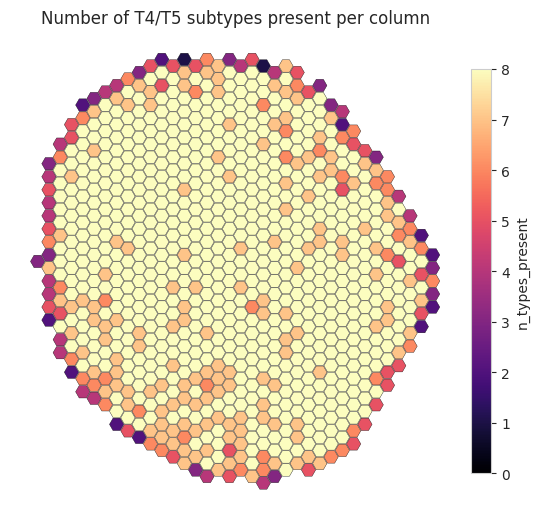

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import Normalize
import matplotlib as mpl

def plot_n_subtypes_per_column(
    column_summary,
    value_col="n_types_present",
    hexsize=1.0,
    rotate=-np.pi/6,
    cmap="viridis",
    vmin=0,
    vmax=8,
    title="T4/T5 subtype coverage per column",
    label_cols=False,
    ax=None,
):
    df = column_summary.copy()

    df = df.dropna(subset=["p", "q", value_col]).copy()

    x, y = pq_to_xy(
        df["p"].to_numpy(),
        df["q"].to_numpy(),
        hexsize=hexsize,
        rotate=rotate,
    )

    df["x_plot"] = x
    df["y_plot"] = y

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    else:
        fig = ax.figure

    patches = []
    values = []

    for _, row in df.iterrows():
        patches.append(
            RegularPolygon(
                (row["x_plot"], row["y_plot"]),
                numVertices=6,
                radius=hexsize * 0.95,
                orientation=np.pi / 6,
            )
        )
        values.append(row[value_col])

    norm = Normalize(vmin=vmin, vmax=vmax)

    collection = PatchCollection(
        patches,
        cmap=cmap,
        norm=norm,
        edgecolor="k",
        linewidth=0.25,
    )
    collection.set_array(np.asarray(values))
    ax.add_collection(collection)

    if label_cols:
        for _, row in df.iterrows():
            if row["missing_types"] == "":
                continue
            ax.text(
                row["x_plot"],
                row["y_plot"],
                row["missing_types"],
                ha="center",
                va="center",
                fontsize=6,
                color="k",
                rotation=0,
            )
            
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.axis("off")
    ax.set_title(title)

    cbar = fig.colorbar(
        collection,
        ax=ax,
        shrink=0.75,
        pad=0.02,
    )
    cbar.set_label(value_col)
    cbar.set_ticks(np.arange(vmin, vmax + 1))

    return fig, ax
fig, ax = plt.subplots(figsize=(7, 7))
fig, _ = plot_n_subtypes_per_column(
    column_summary,
    value_col="n_types_present",
    cmap="magma",
    vmin=0,
    vmax=8,
    title="Number of T4/T5 subtypes present per column",
    label_cols=False,
    ax=ax,
)
plt.show()

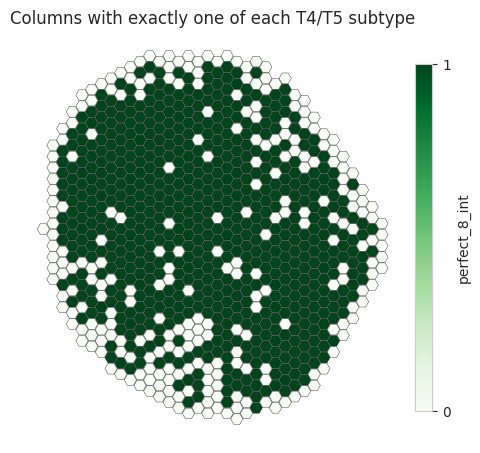

In [41]:
column_summary["perfect_8_int"] = column_summary["perfect_8"].astype(int)

fig, ax = plot_n_subtypes_per_column(
    column_summary,
    value_col="perfect_8_int",
    cmap="Greens",
    vmin=0,
    vmax=1,
    title="Columns with exactly one of each T4/T5 subtype",
)
plt.show()